In [ ]:
!pip install -q torchmetrics[image] scikit-image

import os
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric
from torchmetrics.image.fid import FrechetInceptionDistance
import matplotlib.pyplot as plt

def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

transform = transforms.Compose([transforms.ToTensor()])
full_train_data = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
official_test_data = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

full_dataset = torch.utils.data.ConcatDataset([full_train_data, official_test_data])
train_size = int(0.8 * len(full_dataset))
val_size = int(0.1 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

FASHION_CLASSES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
print(f"Setup selesai pada {device}. Test set: {len(test_dataset)} citra.")

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.57MB/s]

Setup selesai pada cuda. Test set: 7000 citra.


In [ ]:
# 1. Vanilla Autoencoder (Latent Dim = 64)
class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x.view(-1, 784))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


# 2. Sparse Autoencoder (Overcomplete Hidden = 256 + L1 Sparsity Penalty)
class SparseAE(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, hidden_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x.view(-1, 784))

    def decode(self, h):
        return self.decoder(h).view(-1, 1, 28, 28)

    def forward(self, x):
        h = self.encode(x)
        return self.decode(h), h


# 3. Variational Autoencoder / VAE (Latent Dim = 64)
class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.fc_dec1 = nn.Linear(latent_dim, 256)
        self.fc_dec2 = nn.Linear(256, 784)

    def encode(self, x):
        h = F.relu(self.fc1(x.view(-1, 784)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = F.relu(self.fc_dec1(z))
        return torch.sigmoid(self.fc_dec2(h)).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss_function(recon_x, x, mu, logvar):
    # MSE per sampel + KL Divergence (beta=0.001 agar rekonstruksi tajam dan prior tetap teratur)
    recon_loss = F.mse_loss(recon_x, x, reduction='sum') / x.size(0)
    kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon_loss + 0.001 * kld_loss

In [ ]:
EPOCHS = 25
loss_history = {"Vanilla AE": [], "Sparse AE": [], "VAE": []}
train_times = {}

# --- A. Training Vanilla AE ---
vanilla_ae = VanillaAE(latent_dim=64).to(device)
opt_vae_plain = torch.optim.Adam(vanilla_ae.parameters(), lr=1e-3)

print("=== Training Vanilla Autoencoder ===")
epoch_durations = []
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    vanilla_ae.train()
    running_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        recon, _ = vanilla_ae(x)
        loss = F.mse_loss(recon, x)
        opt_vae_plain.zero_grad()
        loss.backward()
        opt_vae_plain.step()
        running_loss += loss.item() * x.size(0)
    epoch_durations.append(time.time() - t0)
    avg_loss = running_loss / len(train_dataset)
    loss_history["Vanilla AE"].append(avg_loss)
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | Loss: {avg_loss:.6f}")
train_times["Vanilla AE"] = np.mean(epoch_durations)

# --- B. Training Sparse AE (Penalti L1: lambda * ||h||_1) ---
sparse_ae = SparseAE(hidden_dim=256).to(device)
opt_sae = torch.optim.Adam(sparse_ae.parameters(), lr=1e-3)
LAMBDA_L1 = 1e-4

print("\n=== Training Sparse Autoencoder ===")
epoch_durations = []
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    sparse_ae.train()
    running_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        recon, h = sparse_ae(x)
        mse_loss = F.mse_loss(recon, x)
        l1_penalty = LAMBDA_L1 * torch.mean(torch.abs(h))
        loss = mse_loss + l1_penalty
        opt_sae.zero_grad()
        loss.backward()
        opt_sae.step()
        running_loss += loss.item() * x.size(0)
    epoch_durations.append(time.time() - t0)
    avg_loss = running_loss / len(train_dataset)
    loss_history["Sparse AE"].append(avg_loss)
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | Total Loss: {avg_loss:.6f}")
train_times["Sparse AE"] = np.mean(epoch_durations)

# --- C. Training VAE ---
vae_model = VAE(latent_dim=64).to(device)
opt_vae = torch.optim.Adam(vae_model.parameters(), lr=1e-3)

print("\n=== Training Variational Autoencoder (VAE) ===")
epoch_durations = []
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    vae_model.train()
    running_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        recon, mu, logvar = vae_model(x)
        loss = vae_loss_function(recon, x, mu, logvar)
        opt_vae.zero_grad()
        loss.backward()
        opt_vae.step()
        running_loss += loss.item() * x.size(0)
    epoch_durations.append(time.time() - t0)
    avg_loss = running_loss / len(train_dataset)
    loss_history["VAE"].append(avg_loss)
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | ELBO Loss: {avg_loss:.4f}")
train_times["VAE"] = np.mean(epoch_durations)

# Simpan checkpoints & riwayat loss untuk Figur 5 di notebook berikutnya
torch.save(vanilla_ae.state_dict(), "checkpoints/vanilla_ae.pth")
torch.save(sparse_ae.state_dict(), "checkpoints/sparse_ae.pth")
torch.save(vae_model.state_dict(), "checkpoints/vae.pth")
np.save("checkpoints/ae_loss_history.npy", loss_history)

=== Training Vanilla Autoencoder ===
Epoch 05 | Loss: 0.012427
Epoch 10 | Loss: 0.009952
Epoch 15 | Loss: 0.009015
Epoch 20 | Loss: 0.008522
Epoch 25 | Loss: 0.008201

=== Training Sparse Autoencoder ===
Epoch 05 | Total Loss: 0.006878
Epoch 10 | Total Loss: 0.004781
Epoch 15 | Total Loss: 0.004011
Epoch 20 | Total Loss: 0.003681
Epoch 25 | Total Loss: 0.003528

=== Training Variational Autoencoder (VAE) ===
Epoch 05 | ELBO Loss: 8.9205
Epoch 10 | ELBO Loss: 6.9381
Epoch 15 | ELBO Loss: 6.1061
Epoch 20 | ELBO Loss: 5.6424
Epoch 25 | ELBO Loss: 5.3814


In [ ]:
def measure_latency_64(fn_infer, runs=50):
    # Warmup GPU
    for _ in range(10):
        _ = fn_infer()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(runs):
        _ = fn_infer()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return ((time.time() - t0) / runs) * 1000.0  # dalam milidetik (ms)

def evaluate_ae_metrics(model, name, is_vae=False):
    model.eval()
    mse_list, psnr_list, ssim_list = [], [], []
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            if is_vae:
                mu, _ = model.encode(x)
                recon = model.decode(mu)
            else:
                recon, _ = model(x)
            x_np = x.cpu().numpy()
            rec_np = recon.cpu().numpy()
            for i in range(x_np.shape[0]):
                orig, rec = x_np[i, 0], rec_np[i, 0]
                mse_list.append(np.mean((orig - rec) ** 2))
                psnr_list.append(psnr_metric(orig, rec, data_range=1.0))
                ssim_list.append(ssim_metric(orig, rec, data_range=1.0))

    # Ukur Latency per batch 64 sampel
    dummy_in = torch.randn(64, 1, 28, 28, device=device)
    dummy_z = torch.randn(64, 64, device=device)
    if is_vae:
        lat_ms = measure_latency_64(lambda: model.decode(dummy_z))
    else:
        lat_ms = measure_latency_64(lambda: model(dummy_in))

    print(f"[{name}] Train/Epoch: {train_times[name]:.2f}s | Latency(64): {lat_ms:.3f}ms | "
          f"MSE: {np.mean(mse_list):.6f} | PSNR: {np.mean(psnr_list):.2f}dB | SSIM: {np.mean(ssim_list):.4f}")

print("=== HASIL EVALUASI TEST SET (BAGIAN IV LAPORAN) ===")
evaluate_ae_metrics(vanilla_ae, "Vanilla AE", is_vae=False)
evaluate_ae_metrics(sparse_ae, "Sparse AE", is_vae=False)
evaluate_ae_metrics(vae_model, "VAE", is_vae=True)

# Hitung FID Score khusus untuk sampel sintetis VAE dari z ~ N(0, I)
fid = FrechetInceptionDistance(feature=64, normalize=True).to(device)
with torch.no_grad():
    for x, _ in test_loader:
        # Konversi grayscale (1 channel) ke 3 channel untuk Inception
        x_rgb = x.repeat(1, 3, 1, 1).to(device)
        fid.update(x_rgb, real=True)

    # Generate 7.000 sampel acak VAE sepadan dengan ukuran Test Set
    for _ in range(0, len(test_dataset), 128):
        z_prior = torch.randn(128, 64, device=device)
        gen_imgs = vae_model.decode(z_prior).repeat(1, 3, 1, 1)
        fid.update(gen_imgs, real=False)

vae_fid = fid.compute().item()
print(f"[VAE Generative FID Score]: {vae_fid:.2f}")

=== HASIL EVALUASI TEST SET (BAGIAN IV LAPORAN) ===
[Vanilla AE] Train/Epoch: 6.85s | Latency(64): 1.418ms | MSE: 0.008450 | PSNR: 21.75dB | SSIM: 0.7846
[Sparse AE] Train/Epoch: 6.25s | Latency(64): 0.556ms | MSE: 0.003607 | PSNR: 25.45dB | SSIM: 0.8835
[VAE] Train/Epoch: 6.84s | Latency(64): 0.103ms | MSE: 0.006777 | PSNR: 22.77dB | SSIM: 0.8231


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 215MB/s]


[VAE Generative FID Score]: 1.73


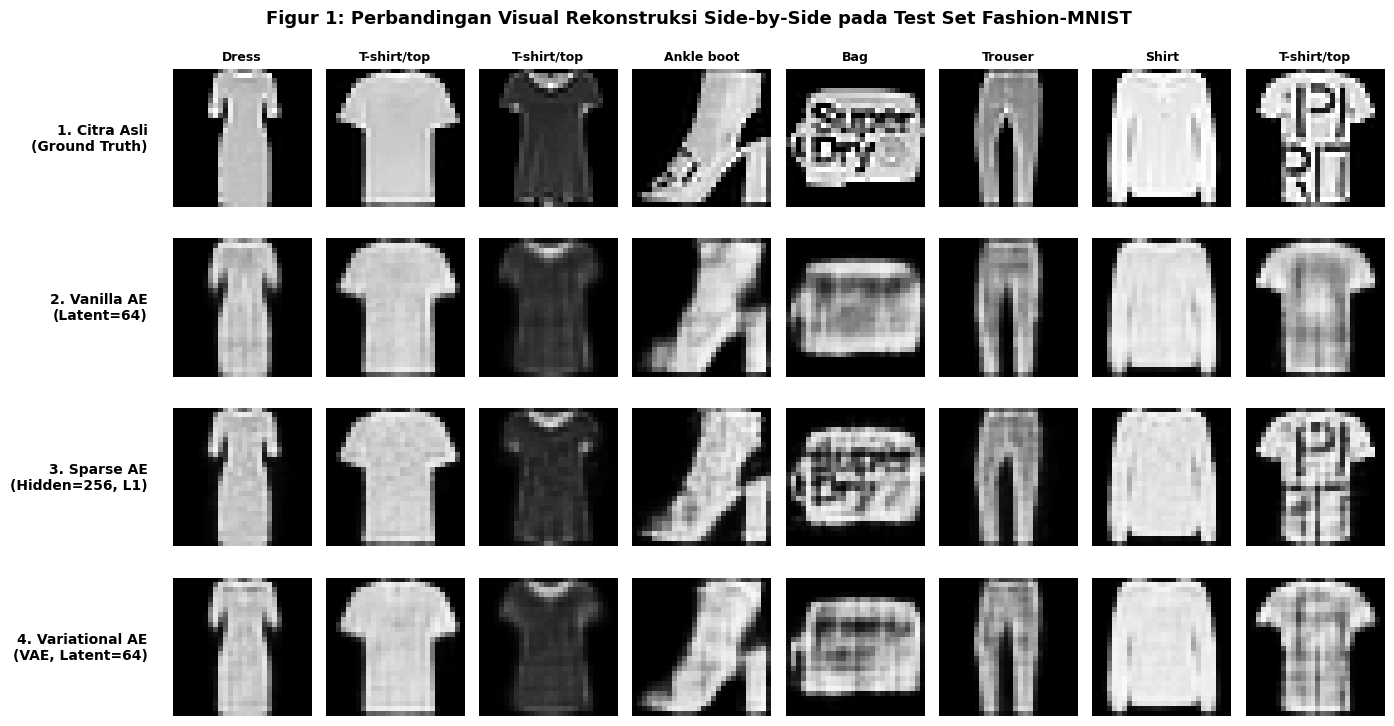

In [ ]:
sample_x, sample_y = next(iter(test_loader))
sample_x = sample_x[:8].to(device)

vanilla_ae.eval()
sparse_ae.eval()
vae_model.eval()

with torch.no_grad():
    rec_vanilla, _ = vanilla_ae(sample_x)
    rec_sparse, _ = sparse_ae(sample_x)
    mu, _ = vae_model.encode(sample_x)
    rec_vae = vae_model.decode(mu)

fig, axes = plt.subplots(4, 8, figsize=(14, 7.5))
titles = [
    "1. Citra Asli\n(Ground Truth)",
    "2. Vanilla AE\n(Latent=64)",
    "3. Sparse AE\n(Hidden=256, L1)",
    "4. Variational AE\n(VAE, Latent=64)"
]
rows = [sample_x.cpu(), rec_vanilla.cpu(), rec_sparse.cpu(), rec_vae.cpu()]

for r_idx, (imgs, title) in enumerate(zip(rows, titles)):
    for c_idx in range(8):
        ax = axes[r_idx, c_idx]
        ax.imshow(imgs[c_idx, 0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if r_idx == 0:
            ax.set_title(FASHION_CLASSES[sample_y[c_idx].item()], fontsize=9, fontweight="bold")
    axes[r_idx, 0].text(-0.18, 0.5, title, transform=axes[r_idx, 0].transAxes,
                        fontsize=10, fontweight="bold", va="center", ha="right")

plt.suptitle("Figur 1: Perbandingan Visual Rekonstruksi Side-by-Side pada Test Set Fashion-MNIST", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("results/figur_1_rekonstruksi.png", dpi=300, bbox_inches="tight")
plt.show()